# Random Forest For Classification

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import plot_tree

In [8]:
titanic = sns.load_dataset("titanic")

features = ["pclass", "sex", "fare", "embarked", "age"]
target = ["survived"]

# handle missing data
imp_median = SimpleImputer(strategy="median")
titanic[["age"]] = imp_median.fit_transform(titanic[["age"]])

imp_freq = SimpleImputer(strategy="most_frequent")
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

# encode
le = LabelEncoder()

titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])

X = titanic[features]
y = titanic["survived"]

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [9]:
# Decision Tree, without pruning to see overfitting happens
model = DecisionTreeClassifier()

model.fit(X_train, y_train)

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Training accuracy: ", accuracy_score(y_train, y_pred_train) * 100, "%")
print("Testing accuracy: ", accuracy_score(y_test, y_pred_test) * 100, "%")

# Overfitting happens normal in Decision Trees.

Training accuracy:  97.91332263242376 %
Testing accuracy:  77.61194029850746 %


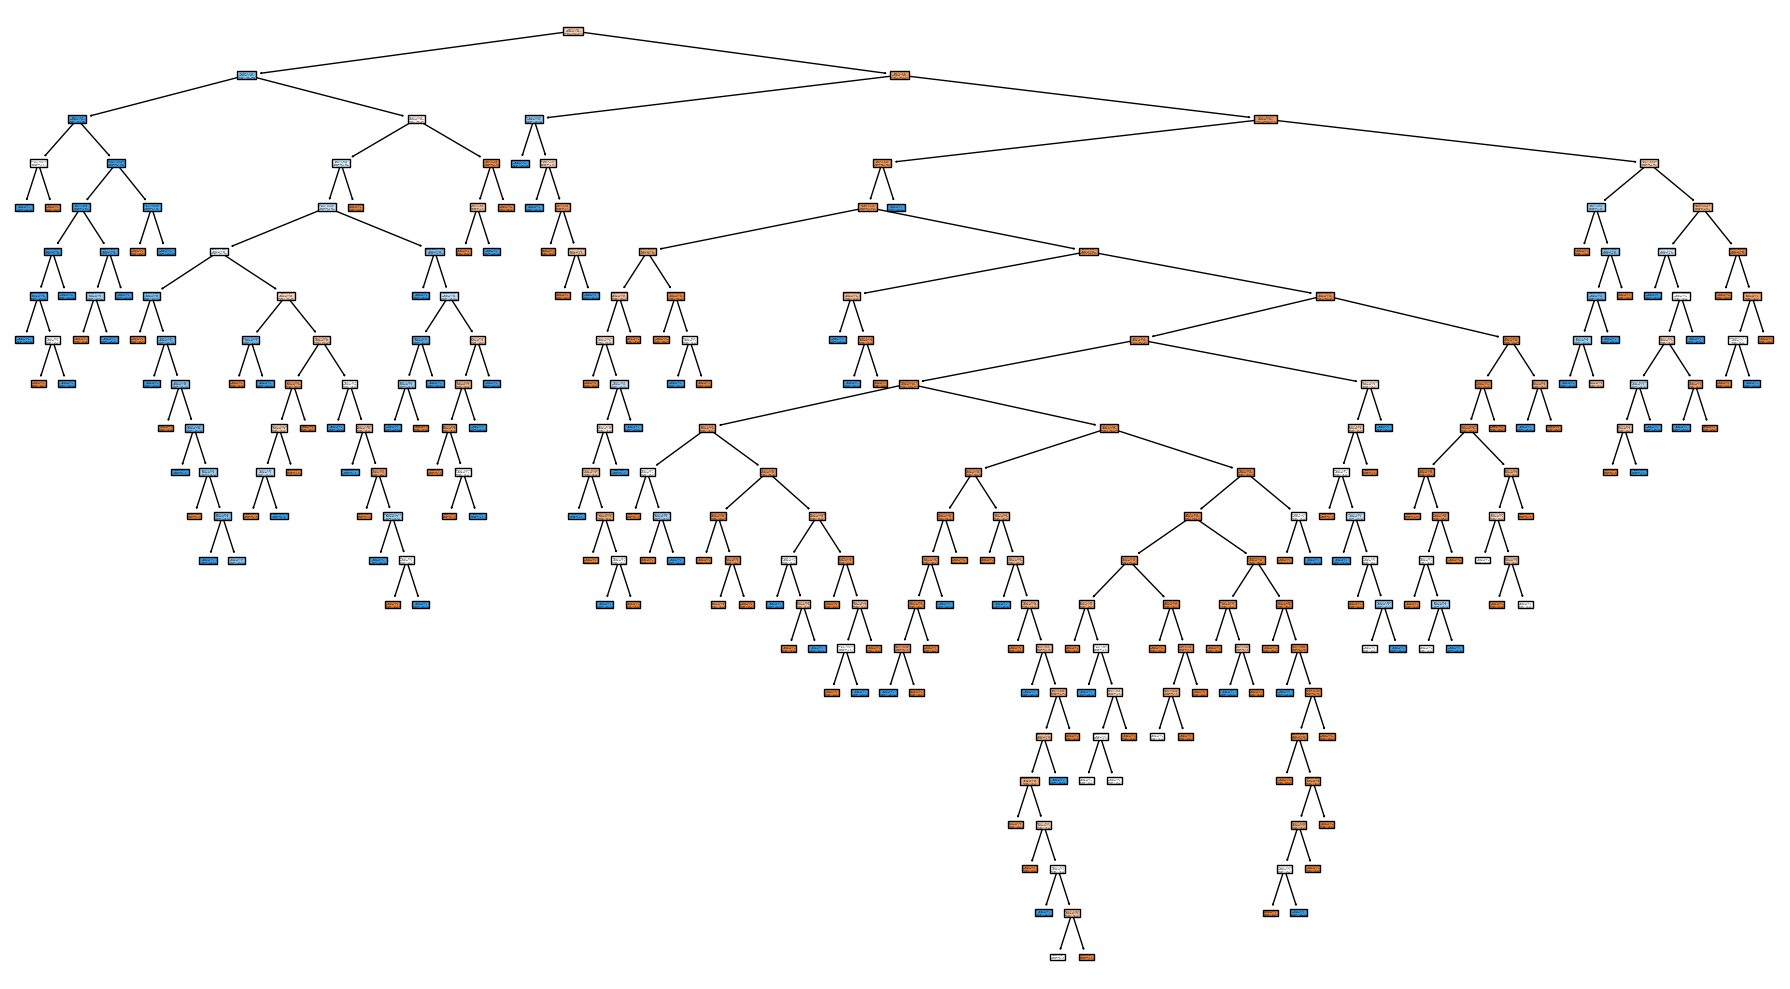

In [10]:
plt.figure(figsize=(18, 10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died", "Survived"],
    filled=True,
)

plt.tight_layout()

# Applying Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=101,  # we might need to do hyperparamter tuning to find best n_estimators
    criterion='gini',
    oob_score=True,
    bootstrap=True,

) # keep numbers in odd 

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print("Testing accuracy:", accuracy_score(y_test, y_pred) * 100, "%")
print("OOB score: ", rf.oob_score_ * 100, "%")

# Testing accuracy is near to OOB score, means no overfitting, RF is a bagging method, reduces overfitting.

Testing accuracy: 79.8507462686567 %
OOB score:  80.89887640449437 %


# Bagging Classifiers

In [12]:
from sklearn.ensemble import BaggingClassifier

# Creating base model

base_model =  DecisionTreeClassifier()

bagging = BaggingClassifier(
    base_model,
    n_estimators=101,

)

bagging.fit(X_train, y_train)

y_pred = bagging.predict(X_test)
print("Testing accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

Testing accuracy: 76.86567164179104 %
